In [1]:
#Inicialización de la estructura del proyecto

from pathlib import Path

# Directorio principal del proyecto
PROJECT_DIR = Path("/content/scout")

# Estructura inicial
carpetas = [
    "data/futdataset",
    "models",
    "src",
    "notebooks",
    "outputs/videos",
    "outputs/detections",
    "config",
]

for carpeta in carpetas:
    (PROJECT_DIR / carpeta).mkdir(parents=True, exist_ok=True)

# Archivos iniciales
archivos = {
    "src/__init__.py": "",
    "requirements.txt": "",
    "README.md": "# Scout\nProyecto de detección y reidentificación de jugadores.",
    "config/config.yaml": "# Configuración del proyecto\n",
}

for ruta, contenido in archivos.items():
    archivo = PROJECT_DIR / ruta
    if not archivo.exists():
        archivo.write_text(contenido, encoding="utf-8")

print("Estructura creada correctamente:")
for ruta in sorted(PROJECT_DIR.rglob("*")):
    print(ruta.relative_to(PROJECT_DIR))

Estructura creada correctamente:
README.md
config
config/config.yaml
data
data/futdataset
models
notebooks
outputs
outputs/detections
outputs/videos
requirements.txt
src
src/__init__.py


In [2]:

# ==================================================
# INSTALAR DEPENDENCIAS
# ==================================================

%pip install -q roboflow ultralytics opencv-python-headless pandas pyyaml matplotlib "supervision>=0.23.0"
%pip install -q trackers

In [3]:

# ==================================================
# 02 — VERIFICACIÓN DEL ENTORNO
# ==================================================

import torch
import ultralytics
import cv2
import pandas as pd
import roboflow
import yaml
import matplotlib
import supervision as sv

from pathlib import Path
from ultralytics import YOLO
from trackers import ByteTrackTracker

print("Supervision:", sv.__version__)
print("ByteTrackTracker disponible:", ByteTrackTracker)
print("BoxAnnotator disponible:", hasattr(sv, "BoxAnnotator"))

print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Supervision:", sv.__version__)

print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Todas las importaciones se completaron correctamente.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Supervision: 0.31.3
ByteTrackTracker disponible: <class 'trackers.core.bytetrack.tracker.ByteTrackTracker'>
BoxAnnotator disponible: True
Ultralytics: 8.4.192
OpenCV: 5.0.0
Pandas: 2.2.3
PyTorch: 2.11.0+cu130
Matplotlib: 3.10.0
Supervision: 0.31.3
GPU disponible: True
GPU: Tesla T4
Todas las importaciones se completaron correctamente.


In [4]:
from pathlib import Path

PROJECT_DIR = Path("/content/scout")

print("¿Existe el proyecto?", PROJECT_DIR.exists())
print("\nContenido de /content/scout:")

for ruta in sorted(PROJECT_DIR.rglob("*")):
    if ruta.is_file():
        print("ARCHIVO:", ruta.relative_to(PROJECT_DIR))
    elif ruta.is_dir():
        print("CARPETA:", ruta.relative_to(PROJECT_DIR))

¿Existe el proyecto? True

Contenido de /content/scout:
ARCHIVO: README.md
CARPETA: config
ARCHIVO: config/config.yaml
CARPETA: data
CARPETA: data/futdataset
CARPETA: models
CARPETA: notebooks
CARPETA: outputs
CARPETA: outputs/detections
CARPETA: outputs/videos
ARCHIVO: requirements.txt
CARPETA: src
ARCHIVO: src/__init__.py


In [5]:
from google.colab import userdata
from roboflow import Roboflow
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

api_key = userdata.get("ROBOFLOW_API_KEY")

if not api_key:
    raise ValueError("No se encontró el secreto ROBOFLOW_API_KEY.")

rf = Roboflow(api_key=api_key)
project = rf.workspace("futdataset").project("futdataset")
version = project.version(2)

dataset = version.download(
    "yolov8",
    location=str(DATASET_DIR)
)

print("\nRuta devuelta por Roboflow:", dataset.location)

ruta_descargada = Path(dataset.location)
print("\nArchivos encontrados:")

for ruta in sorted(ruta_descargada.rglob("*")):
    if ruta.is_file():
        print(ruta.relative_to(ruta_descargada))

loading Roboflow workspace...
loading Roboflow project...

Ruta devuelta por Roboflow: /content/scout/data/futdataset

Archivos encontrados:


In [6]:
# Consultar los metadatos de la versión
print("Proyecto:", project.name)
print("Versión:", version.version)

print("\nInformación de la versión:")
print(version)

Proyecto: FutDataset
Versión: 2

Información de la versión:
{
  "name": "FutDataset",
  "type": "object-detection",
  "version": "2",
  "augmentation": {},
  "created": 1755269838.954,
  "preprocessing": {
    "auto-orient": true,
    "resize": {
      "format": "Stretch to",
      "height": 640,
      "width": 640
    }
  },
  "splits": {
    "valid": 102,
    "test": 52,
    "train": 357
  },
  "workspace": "futdataset"
}


In [7]:
#Descargar el dataset y comprobar sus archivos
from pathlib import Path
from roboflow import Roboflow
from google.colab import userdata

api_key = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)

project = rf.workspace("futdataset").project("futdataset")
version = project.version(2)

# Descargar en una carpeta nueva para diagnosticar
DATASET_DIR = Path("/content/scout/data/futdataset_v2")

dataset = version.download(
    model_format="yolov8",
    location=str(DATASET_DIR),
    overwrite=True
)

print("\nRuta devuelta:", dataset.location)

ruta = Path(dataset.location)
archivos = [p for p in ruta.rglob("*") if p.is_file()]

print("Total de archivos encontrados:", len(archivos))
for archivo in archivos[:30]:
    print(archivo.relative_to(ruta))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/scout/data/futdataset_v2 in yolov8:: 100%|██████████| 1034/1034 [00:00<00:00, 3533.85it/s]



Ruta devuelta: /content/scout/data/futdataset_v2
Total de archivos encontrados: 1025
data.yaml
README.dataset.txt
README.roboflow.txt
train/images/GOMCAM-20250704_2113590680_png.rf.d901ff46a943c02f06861a34d9dedbed.jpg
train/images/GOMCAM-20250807_1628430913_png.rf.f3d178afb0ed7d017dbca859b1a5a757.jpg
train/images/GOMCAM-20250704_2102490042_png.rf.8ddc3cfe2a5b80f2f40c2f172211e9a8.jpg
train/images/GOMCAM-20250704_2127180521_png.rf.04267e0adcea19fb15a2ee1985a353ef.jpg
train/images/GOMCAM-20250704_2055170918_png.rf.d940e49e4ed5e22901e38f7fdfe8c99d.jpg
train/images/GOMCAM-20250712_2159490433_png.rf.48c2fcaa4c09f2da7f4d0cbcf9466fec.jpg
train/images/GOMCAM-20250706_2222390270_png.rf.23e777312b87590e38abe314dd0272db.jpg
train/images/GOMCAM-20250708_2212500538_png.rf.3e49a1059891303adc0f5d8d3fcd0a08.jpg
train/images/GOMCAM-20250704_2114140408_png.rf.60c4b46861e3a93af558e386dd6843b7.jpg
train/images/GOMCAM-20250709_2225420676_png.rf.395badf80f64eea5e5563d611bbfb33e.jpg
train/images/GOMCAM-20250

In [8]:
#Validar el dataset
from pathlib import Path
import yaml

DATASET_DIR = Path("/content/scout/data/futdataset_v2")
DATA_YAML = DATASET_DIR / "data.yaml"

# 1. Verificar el archivo de configuración
if not DATA_YAML.exists():
    raise FileNotFoundError(f"No se encontró: {DATA_YAML}")

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("=== CONFIGURACIÓN DEL DATASET ===")
print(yaml.dump(config, allow_unicode=True, sort_keys=False))

# 2. Contar imágenes por conjunto
print("\n=== IMÁGENES ===")

for split in ["train", "valid", "test"]:
    carpeta = DATASET_DIR / split / "images"

    if carpeta.exists():
        imagenes = [
            p for p in carpeta.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]
        print(f"{split}: {len(imagenes)} imágenes")
    else:
        print(f"{split}: NO SE ENCONTRÓ LA CARPETA {carpeta}")

# 3. Comprobar las etiquetas
print("\n=== ETIQUETAS YOLO ===")

for split in ["train", "valid", "test"]:
    carpeta = DATASET_DIR / split / "labels"

    if carpeta.exists():
        etiquetas = list(carpeta.glob("*.txt"))
        print(f"{split}: {len(etiquetas)} archivos de etiquetas")
    else:
        print(f"{split}: NO SE ENCONTRÓ LA CARPETA DE ETIQUETAS")

=== CONFIGURACIÓN DEL DATASET ===
names:
- arbitro
- arquero1
- arquero2
- ball
- equipo1
- equipo2
nc: 6
roboflow:
  license: CC BY 4.0
  project: futdataset
  url: https://universe.roboflow.com/futdataset/futdataset/dataset/2
  version: 2
  workspace: futdataset
test: ../test/images
train: ../train/images
val: ../valid/images


=== IMÁGENES ===
train: 357 imágenes
valid: 102 imágenes
test: 52 imágenes

=== ETIQUETAS YOLO ===
train: 357 archivos de etiquetas
valid: 102 archivos de etiquetas
test: 52 archivos de etiquetas


In [9]:
#5. Crear el primer módulo de detección
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

codigo = """
from pathlib import Path

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
DATA_YAML = DATASET_DIR / "data.yaml"
MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"


def verificar_dataset():
    if not DATA_YAML.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {DATA_YAML}"
        )

    print("Dataset encontrado:", DATA_YAML)
    print("Configuración disponible para entrenar.")


if __name__ == "__main__":
    verificar_dataset()
"""

archivo = SRC_DIR / "detector.py"
archivo.write_text(codigo, encoding="utf-8")

print("Módulo creado:", archivo)
print("Existe data.yaml:", (PROJECT_DIR / "data/futdataset_v2/data.yaml").exists())
print("Existe detector.py:", archivo.exists())

exec(compile(codigo, str(archivo), "exec"))

Módulo creado: /content/scout/src/detector.py
Existe data.yaml: True
Existe detector.py: True
Dataset encontrado: /content/scout/data/futdataset_v2/data.yaml
Configuración disponible para entrenar.


Imagen: GOMCAM-20250704_2055560194_png.rf.bbc02c32e161a6751739e7bb8e619aaa.jpg
Dimensiones: 640 x 640
Etiqueta encontrada: True


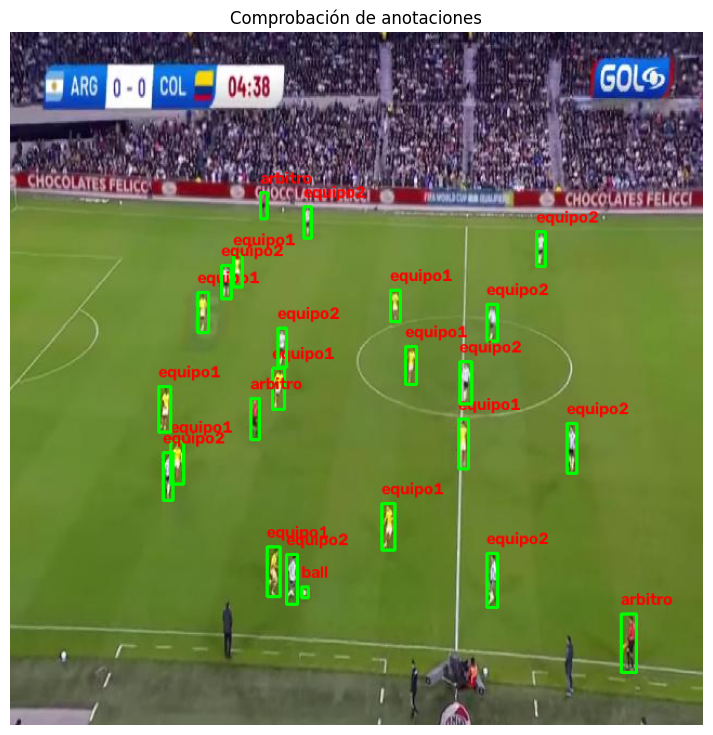

In [10]:
#Visualizar las anotaciones del dataset
from pathlib import Path
import cv2
import yaml
import matplotlib.pyplot as plt
import random

DATASET_DIR = Path("/content/scout/data/futdataset_v2")

with open(DATASET_DIR / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"

images = [
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if not images:
    raise FileNotFoundError("No se encontraron imágenes de entrenamiento.")

image_path = random.choice(images)
label_path = labels_dir / f"{image_path.stem}.txt"

image = cv2.imread(str(image_path))
if image is None:
    raise ValueError(f"No se pudo leer la imagen: {image_path}")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]

print("Imagen:", image_path.name)
print("Dimensiones:", width, "x", height)
print("Etiqueta encontrada:", label_path.exists())

if label_path.exists():
    with open(label_path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            print("Etiqueta con formato inesperado:", line.strip())
            continue

        class_id, x_center, y_center, box_w, box_h = map(float, parts)
        class_id = int(class_id)

        x1 = int((x_center - box_w / 2) * width)
        y1 = int((y_center - box_h / 2) * height)
        x2 = int((x_center + box_w / 2) * width)
        y2 = int((y_center + box_h / 2) * height)

        nombre = names[class_id] if 0 <= class_id < len(names) else f"clase_{class_id}"

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            image, nombre, (x1, max(y1 - 8, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2
        )

plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.axis("off")
plt.title("Comprobación de anotaciones")
plt.show()

In [11]:
#Preparar el entrenamiento de YOLO
from pathlib import Path
import yaml
import torch
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
DATA_YAML = DATASET_DIR / "data.yaml"

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("Clases:", config["names"])
print("Número de clases:", config["nc"])
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset listo:", DATA_YAML.exists())
print("Carpeta de modelos:", (PROJECT_DIR / "models").exists())
print("Carpeta de resultados:", (PROJECT_DIR / "outputs").exists())

Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
Número de clases: 6
GPU disponible: True
GPU: Tesla T4
Dataset listo: True
Carpeta de modelos: True
Carpeta de resultados: True


In [12]:
#Entrenar el modelo
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path("/content/scout")
DATA_YAML = PROJECT_DIR / "data" / "futdataset_v2" / "data.yaml"

# Modelo preentrenado
model = YOLO("yolov8s.pt")

# Entrenamiento inicial
results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project=str(PROJECT_DIR / "outputs"),
    name="deteccion_v1",
    exist_ok=True,
    patience=10,
    save=True,
    plots=True,
    seed=42
)

print("\nEntrenamiento finalizado.")
print("Resultados:", PROJECT_DIR / "outputs" / "deteccion_v1")
print("Mejor modelo:", PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/scout/data/futdataset_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=deteccion_v1, nbs=64, nms=None, opset=None, op

Results saved to /content/scout/outputs/prueba_visual
Imagen: GOMCAM-20250704_2051270247_png.rf.0c6dccea6f06e2dcac09fcd4ae52b50b.jpg
Detecciones: 18


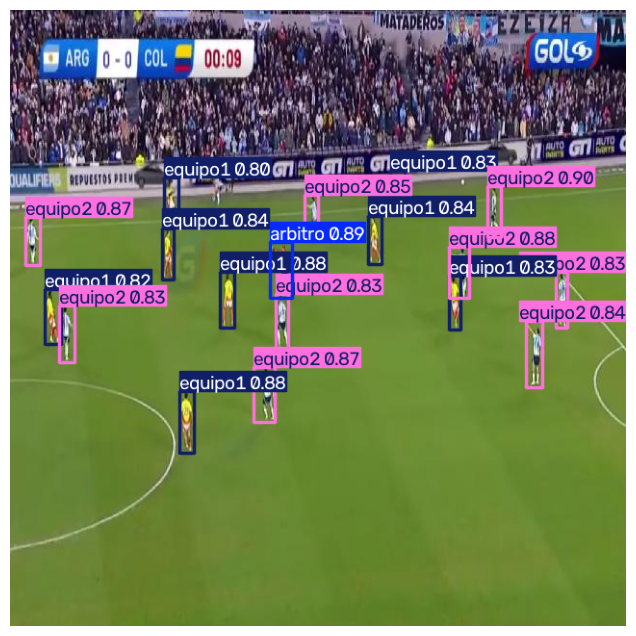

Imagen: GOMCAM-20250807_1626510822_png.rf.99a3f8ebf54718425531d2421e99b508.jpg
Detecciones: 23


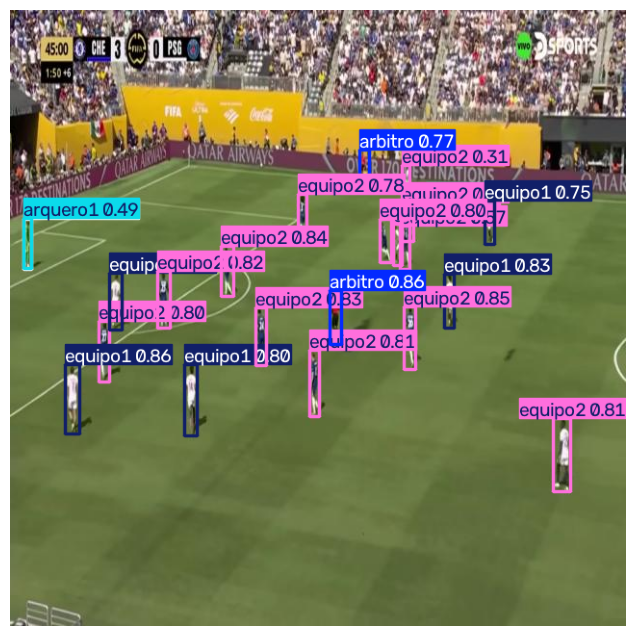

Imagen: GOMCAM-20250704_2114270425_png.rf.b4334a0fc6ff3c4877c714141cd81fe7.jpg
Detecciones: 14


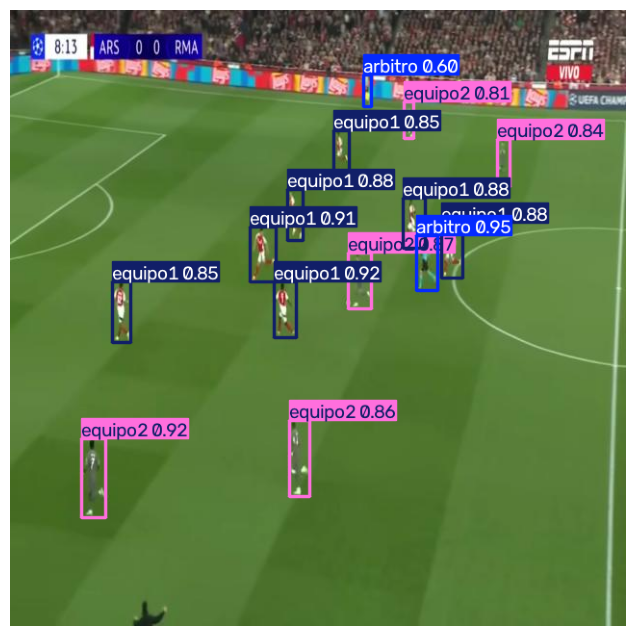

Predicciones guardadas en: /content/scout/outputs/prueba_visual


In [13]:
#9 Probar el modelo con imágenes que no ha visto
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
MODEL_PATH = PROJECT_DIR / "outputs/deteccion_v1/weights/best.pt"
TEST_DIR = PROJECT_DIR / "data/futdataset_v2/test/images"

model = YOLO(str(MODEL_PATH))

imagenes = [
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if len(imagenes) < 3:
    raise ValueError(f"Solo se encontraron {len(imagenes)} imágenes de prueba.")

seleccionadas = random.sample(imagenes, 3)

resultados = model.predict(
    source=[str(p) for p in seleccionadas],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PROJECT_DIR / "outputs"),
    name="prueba_visual",
    exist_ok=True,
    verbose=False
)

for resultado in resultados:
    imagen = resultado.plot()
    imagen = imagen[:, :, ::-1]  # BGR a RGB

    print("Imagen:", Path(resultado.path).name)
    print("Detecciones:", len(resultado.boxes))

    plt.figure(figsize=(14, 8))
    plt.imshow(imagen)
    plt.axis("off")
    plt.show()

print("Predicciones guardadas en:",
      PROJECT_DIR / "outputs" / "prueba_visual")

In [14]:
#comprobar si el modelo detecta algún balón
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
MODEL_PATH = PROJECT_DIR / "outputs/deteccion_v1/weights/best.pt"
TEST_DIR = PROJECT_DIR / "data/futdataset_v2/test/images"

model = YOLO(str(MODEL_PATH))

imagenes = [
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

print("Total de imágenes:", len(imagenes))
print("Clase del balón:", {
    k: v for k, v in model.names.items() if v == "ball"
})

for umbral in [0.05, 0.10, 0.25]:
    imagenes_con_balon = 0
    total_balones = 0

    for ruta in imagenes:
        resultado = model.predict(
            source=str(ruta),
            imgsz=640,
            conf=umbral,
            device=0,
            verbose=False
        )[0]

        if resultado.boxes is not None:
            clases = resultado.boxes.cls.cpu().tolist()
            cantidad = sum(
                1 for clase in clases
                if model.names[int(clase)] == "ball"
            )
            total_balones += cantidad

            if cantidad > 0:
                imagenes_con_balon += 1

    print(
        f"Umbral {umbral:.2f} | "
        f"Imágenes con balón: {imagenes_con_balon} | "
        f"Detecciones de balón: {total_balones}"
    )

Total de imágenes: 52
Clase del balón: {3: 'ball'}
Umbral 0.05 | Imágenes con balón: 34 | Detecciones de balón: 60
Umbral 0.10 | Imágenes con balón: 31 | Detecciones de balón: 39
Umbral 0.25 | Imágenes con balón: 24 | Detecciones de balón: 27


Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
Imágenes anotadas con balón: 309
Imagen: GOMCAM-20250706_2216350970_png.rf.952e81f4d67a1e65daf1d4254b8877c9.jpg


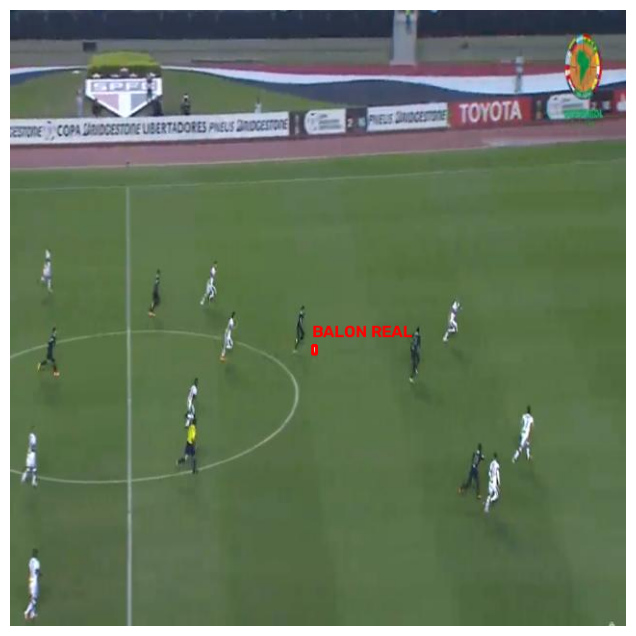

Imagen: GOMCAM-20250709_2238280343_png.rf.e9273aba9754b67c2df0f89c00ef0668.jpg


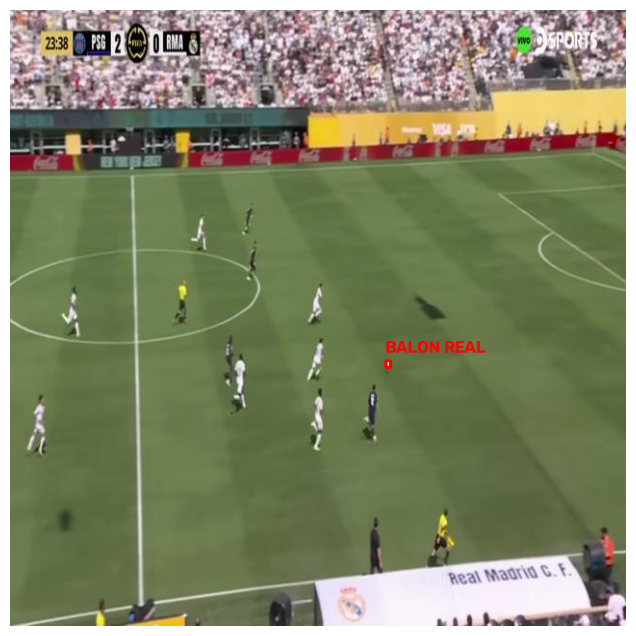

Imagen: GOMCAM-20250709_2238040229_png.rf.63f7ea83c90c744b585d8f5f2805bfe1.jpg


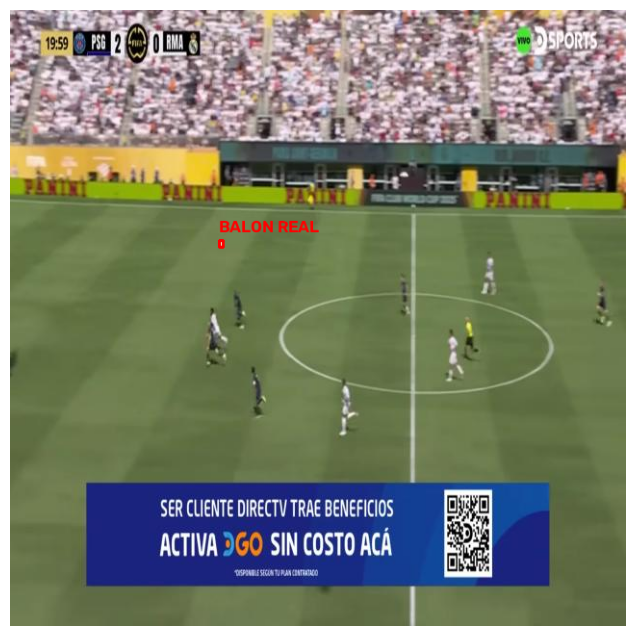

In [15]:
#verificar las anotaciones reales del balón
from pathlib import Path
import yaml
import cv2
import matplotlib.pyplot as plt
import random

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"

with open(DATASET_DIR / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("Clases:", config["names"])

images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"

imagenes_con_balon = []

for etiqueta in labels_dir.glob("*.txt"):
    with open(etiqueta, "r") as f:
        lineas = f.readlines()

    if any(linea.split()[0] == "3" for linea in lineas if linea.strip()):
        imagen = images_dir / f"{etiqueta.stem}.jpg"

        if not imagen.exists():
            for extension in [".png", ".jpeg", ".webp"]:
                alternativa = images_dir / f"{etiqueta.stem}{extension}"
                if alternativa.exists():
                    imagen = alternativa
                    break

        if imagen.exists():
            imagenes_con_balon.append((imagen, etiqueta))

print("Imágenes anotadas con balón:", len(imagenes_con_balon))

for imagen_path, etiqueta_path in random.sample(
    imagenes_con_balon, min(3, len(imagenes_con_balon))
):
    imagen = cv2.imread(str(imagen_path))
    alto, ancho = imagen.shape[:2]

    with open(etiqueta_path, "r") as f:
        for linea in f:
            datos = linea.split()
            if len(datos) != 5 or datos[0] != "3":
                continue

            _, xc, yc, w, h = map(float, datos)
            x1 = int((xc - w / 2) * ancho)
            y1 = int((yc - h / 2) * alto)
            x2 = int((xc + w / 2) * ancho)
            y2 = int((yc + h / 2) * alto)

            cv2.rectangle(imagen, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(
                imagen, "BALON REAL",
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2
            )

    print("Imagen:", imagen_path.name)
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

In [16]:
#Celda de diagnóstico
#Esta celda compara las anotaciones reales con las predicciones del modelo en las 52 imágenes de prueba.

from pathlib import Path
import yaml
from ultralytics import YOLO

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"
MODEL_PATH = PROJECT_DIR / "outputs" / "deteccion_v1" / "weights" / "best.pt"

with open(DATASET_DIR / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

# Funciona tanto si names es una lista como si es un diccionario
if isinstance(names, list):
    ball_id = names.index("ball")
else:
    ball_id = next(int(k) for k, v in names.items() if v == "ball")

print("Clases:", names)
print("ID del balón:", ball_id)

model = YOLO(str(MODEL_PATH))

metrics = model.val(
    data=str(DATASET_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.50,
    plots=True,
    project=str(PROJECT_DIR / "outputs"),
    name="diagnostico_balon",
    exist_ok=True,
    verbose=False
)

print("\n--- MÉTRICAS DEL BALÓN EN TEST ---")
print("Precisión:", round(float(metrics.box.p[ball_id]), 3))
print("Recall:", round(float(metrics.box.r[ball_id]), 3))
print("mAP50:", round(float(metrics.box.ap50[ball_id]), 3))
print("mAP50-95:", round(float(metrics.box.ap[ball_id]), 3))

print("\nResultados guardados en:")
print(PROJECT_DIR / "outputs" / "diagnostico_balon")

Clases: ['arbitro', 'arquero1', 'arquero2', 'ball', 'equipo1', 'equipo2']
ID del balón: 3
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1639.2±464.9 MB/s, size: 41.6 KB)
val: Scanning /content/scout/data/futdataset_v2/test/labels... 52 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 1.6Kit/s 0.0s
val: New cache created: /content/scout/data/futdataset_v2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s
                   all         52        929      0.941      0.828       0.87      0.634
Speed: 7.1ms preprocess, 14.7ms inference, 0.1ms loss, 20.2ms postprocess per image
Results saved to /content/scout/outputs/diagnostico_balon

--- MÉTRICAS DEL BALÓN EN TEST ---
Precisión: 0.982
Recall: 0.37
mAP50: 0.511
mAP50-95: 0

Imagen: GOMCAM-20250708_2217380577_png.rf.293c750eaa298e9bf1db7a22798512bc.jpg
Caja original del balón: 4 × 5 píxeles


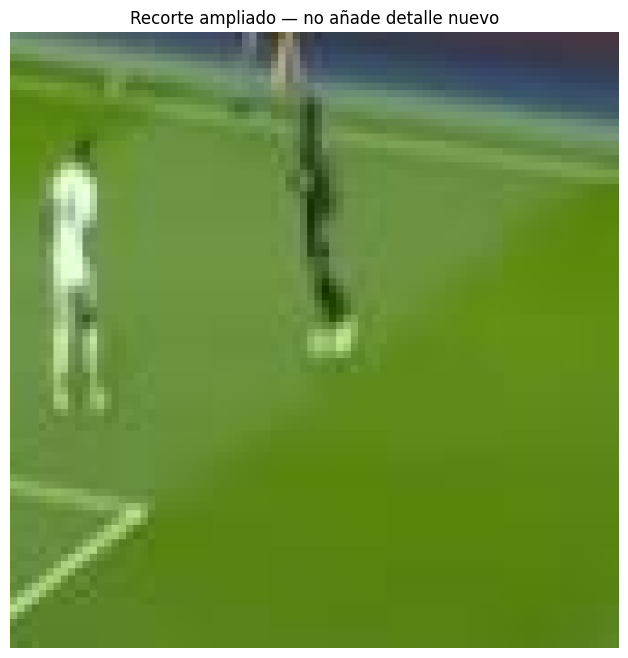

Imagen: GOMCAM-20250704_2102020642_png.rf.be93dd9fb8b004516100dff27e2658a6.jpg
Caja original del balón: 7 × 10 píxeles


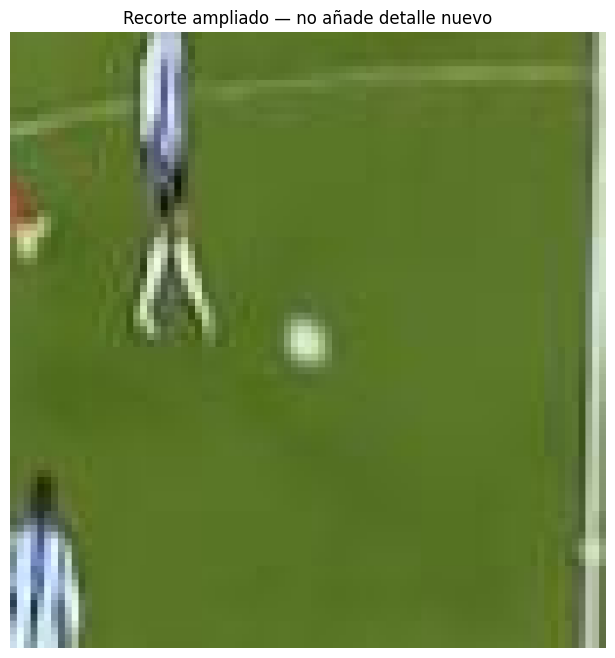

Imagen: GOMCAM-20250705_2047570968_png.rf.102099e0ff61e54a5bc449209f230f5a.jpg
Caja original del balón: 5 × 7 píxeles


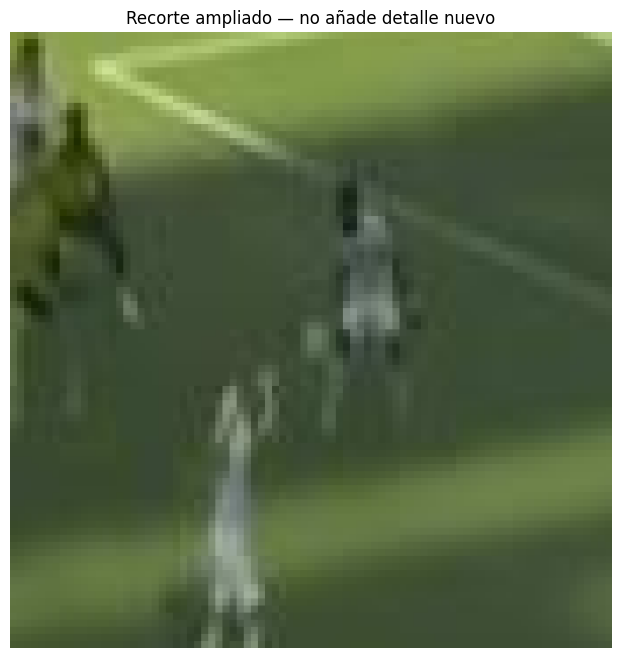

In [17]:
#ejemplo visualizar el balón ampliado
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

PROJECT_DIR = Path("/content/scout")
DATASET_DIR = PROJECT_DIR / "data" / "futdataset_v2"

images_dir = DATASET_DIR / "train" / "images"
labels_dir = DATASET_DIR / "train" / "labels"
ball_id = 3

candidatas = []

for label_path in labels_dir.glob("*.txt"):
    lineas = [
        linea.split()
        for linea in label_path.read_text().splitlines()
        if linea.strip()
    ]

    balones = [
        datos for datos in lineas
        if len(datos) == 5 and int(datos[0]) == ball_id
    ]

    if not balones:
        continue

    image_path = next(
        (images_dir / f"{label_path.stem}{ext}"
         for ext in [".jpg", ".jpeg", ".png", ".webp"]
         if (images_dir / f"{label_path.stem}{ext}").exists()),
        None
    )

    if image_path:
        candidatas.append((image_path, balones))

seleccionadas = random.sample(candidatas, min(3, len(candidatas)))

for image_path, balones in seleccionadas:
    imagen = cv2.imread(str(image_path))
    alto, ancho = imagen.shape[:2]

    # Seleccionar la primera anotación del balón
    _, xc, yc, w, h = map(float, balones[0])

    x1 = int((xc - w / 2) * ancho)
    y1 = int((yc - h / 2) * alto)
    x2 = int((xc + w / 2) * ancho)
    y2 = int((yc + h / 2) * alto)

    # Recorte ampliado con margen alrededor del balón
    margen = 40
    xa, ya = max(0, x1 - margen), max(0, y1 - margen)
    xb, yb = min(ancho, x2 + margen), min(alto, y2 + margen)

    recorte = imagen[ya:yb, xa:xb]
    ampliado = cv2.resize(
        recorte, None, fx=6, fy=6,
        interpolation=cv2.INTER_NEAREST
    )

    print("Imagen:", image_path.name)
    print("Caja original del balón:", x2 - x1, "×", y2 - y1, "píxeles")

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(ampliado, cv2.COLOR_BGR2RGB))
    plt.title("Recorte ampliado — no añade detalle nuevo")
    plt.axis("off")
    plt.show()

In [18]:
#comprobar nuestro entorno antes de instalar nada
import torch
import ultralytics
import cv2

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)

try:
    import supervision as sv
    print("Supervision:", sv.__version__)
except ImportError:
    print("Supervision: no está instalado")

try:
    import inference
    print("Inference: instalado")
except ImportError:
    print("Inference: no está instalado")

PyTorch: 2.11.0+cu130
CUDA disponible: True
Ultralytics: 8.4.192
OpenCV: 5.0.0
Supervision: 0.31.3
Inference: no está instalado
